## Randomized neural networks on Bickley jet

In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
import time
from deeptime.data import BickleyJet
from matplotlib.animation import FuncAnimation
from jax import random
import importlib
import optimal_ranndy
import utils
importlib.reload(optimal_ranndy)
importlib.reload(utils)
from optimal_ranndy import RaNNDy, VAMPnets
from utils import nice_2d_plot
import sys
sys.path.append("/home/s2421480/Documents/PhD_first_year/Extended_summer_project/Codes/d3s/")
import d3s.domain as domain


plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'        
plt.rcParams['font.serif'] = ['Computer Modern Serif'] 

cluster_colors = ["teal", "darkgreen", "indigo", "darkorange", "slateblue", "saddlebrown", "dimgray", "darkkhaki", "crimson"]


plt.ion()

In [2]:
# # Generating dataset

state = np.random.RandomState(seed=123)  

def draw_initial_positions(n):
    # draws n initial positions in the system's domain
    X = np.vstack((state.uniform(0, 20, (n,)),
                   state.uniform(-3, 3, (n, ))))
    return X.T


def forward_transform(X, h=1e-3):
    simulator = BickleyJet(h=h, n_steps=int(1. / h / 10))
    return simulator.trajectory(t0=0, x0=X, length=401)


def psi(x):  # transform the trajectory to periodic 3D trajectory
    return jnp.array([jnp.cos(2*jnp.pi*x[0,:]/20), jnp.sin(2*jnp.pi*x[0,:]/20), x[1,:]/3])


In [3]:
## Simulate the trajectory 

Xinit = draw_initial_positions(5000)
traj = forward_transform(Xinit)
print("Data having {} particles for {} "
      "timesteps in {} dimensions.".format(*traj.shape))

Data having 5000 particles for 401 timesteps in 2 dimensions.


In [4]:
#  Data and Domain

Xa = traj[:, 0].T
Ya = traj[:, -1].T

X = psi(Xa)
Y = psi(Ya)


# define domain
bounds = jnp.array([[0, 20], [-3, 3]])
boxes = jnp.array([100, 100])
Omega = domain.discretization(bounds, boxes)

/tmp/ipykernel_6797/1381980907.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scat = ax1.scatter(Xa[0, :], Xa[1, :], c='blue', cmap="hsv")


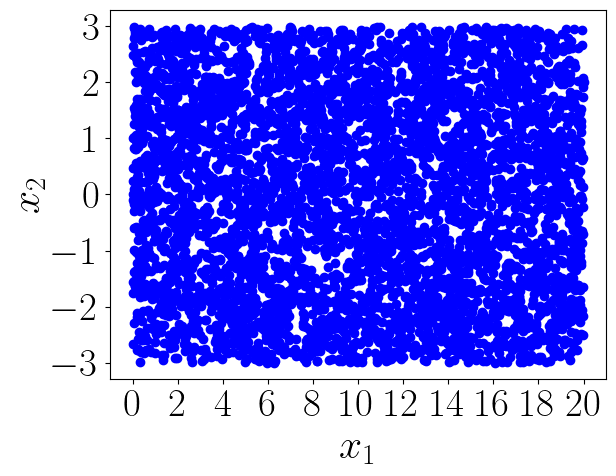

In [7]:
## Visualize trajectory
with nice_2d_plot(xlabel='$x_1$', ylabel='$x_2$', xticks=np.arange(0, 22, 2), yticks=np.arange(-3, 4, 1)) as (fig1, ax1):
    scat = ax1.scatter(Xa[0, :], Xa[1, :], c='blue', cmap="hsv")  
    

def update(frame):
    coords = traj[:, frame, :]

    scat.set_cmap("coolwarm")

    scat.set_offsets(coords)
    #scat.set_array(colors)
    return scat,

frames = [i for i in range(400)]
ani = FuncAnimation(fig1, update, frames=frames, interval=200, blit=True)

# from IPython.display import HTML
# HTML(ani.to_jshtml())
ani.save('bickley_video.mp4')

In [42]:
## Run this cell to apply RaNNDy for the forward-backward operator

operator = 'forward_backward'
hidden_sizes = [12000, 128]
activation = "tanh"  # activation function
init_weights = 'normal'
init_bias = 'normal'  # Initialization of weights and biases
init_weights_std = 0.5  # Standard deviation for normal initialization
init_bias_std = 0.1  # Scale for uniform initialization
# direct_link=False  # Whether to use direct link to input # TODO:
random_state = 1  # Random state for reproducibility
n_eigfuncs = 9  # Number of eigenfunctions to compute
w_init = [None, jnp.float32(0.001), jnp.float32(0.001)]
#key = random.PRNGKey(seed=0)

ranndy = RaNNDy(
    X=X,
    operator=operator,
    hidden_sizes=hidden_sizes,
    activation=activation,
    init_weights_dist=init_weights, 
    init_weights_std=init_weights_std,
    init_bias_dist=init_bias,
    init_bias_std=init_bias_std,
    #direct_link=direct_link,
    random_state=random_state,
    vampnet=False
)

#params = ranndy.init(key, jnp.ones_like(X), w=1)

start_time = time.time()  # Start time for RNN eigendecomposition
# eigvals and eigenvectors approximation
eigvals_i, eigvecs_i = ranndy.operator_eig_decomp(
    w=w_init,
    X=X,
    Y=Y,
    Z=None,
    n=n_eigfuncs,
    epsilon=1e-5,
    )

end_time = time.time()  # End time for RNN eigendecomposition
time_rnn = end_time - start_time
print(f"RNN eigendecomposition time: {time_rnn:.2f} seconds")


RNN eigendecomposition time: 0.73 seconds


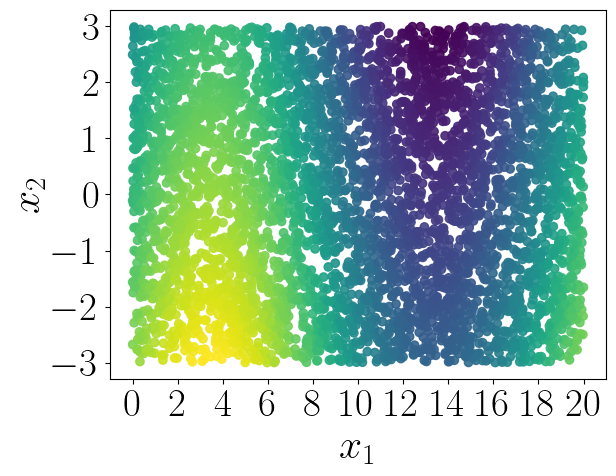

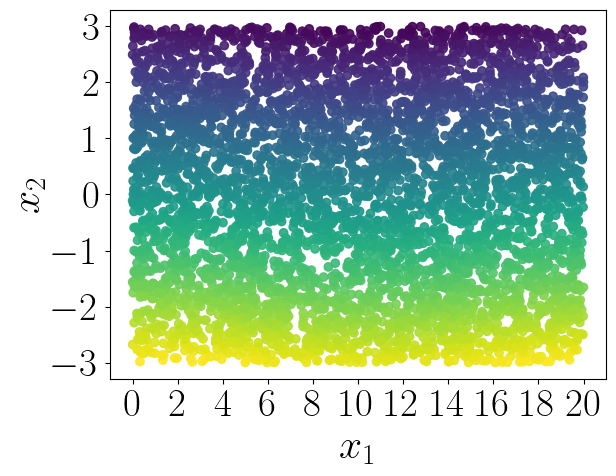

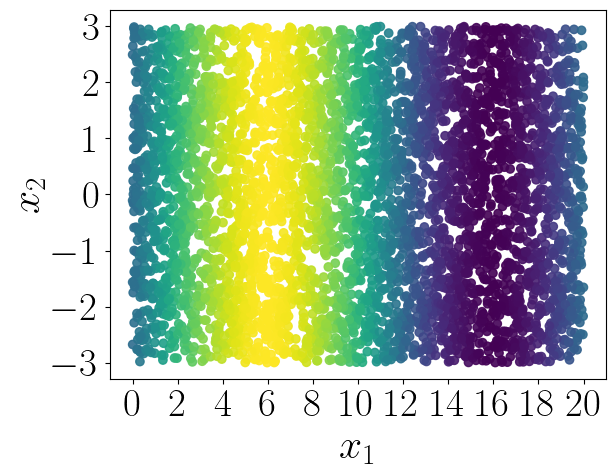

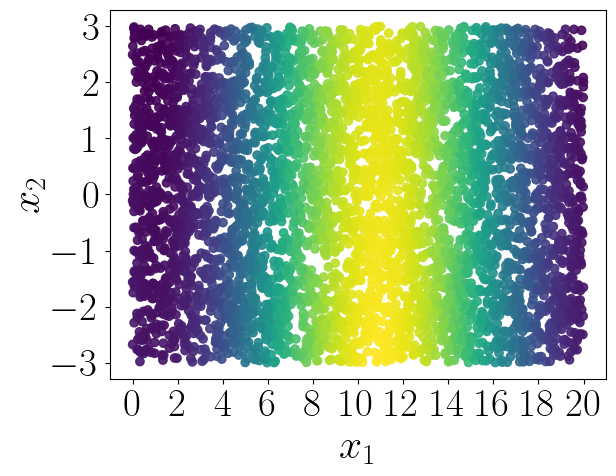

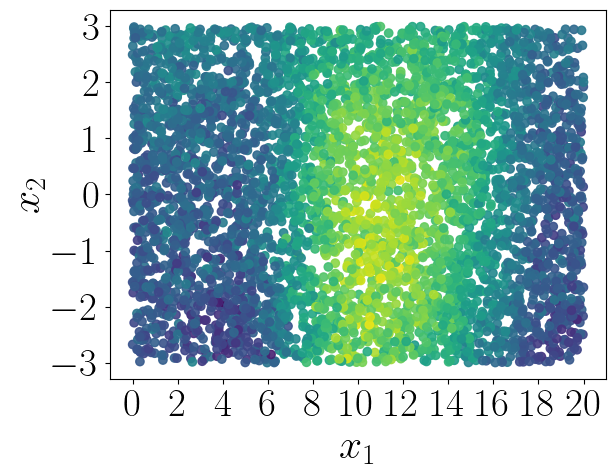

LinAlgError: Matrix is not positive definite

In [43]:
# plot initial eigenfunctions for ranndy

eigfuncs_i = ranndy.eigenfunctions(
        w=w_init,
        eigvecs=eigvecs_i,
        domain=X,
        )
       
for i in range(5):
    #plt.figure(figsize=(3, 2))
    with nice_2d_plot(xlabel='$x_1$', ylabel='$x_2$', xticks=np.arange(0, 22, 2), yticks=np.arange(-3, 4, 1)) as (fig2, ax2):
        ax2.scatter(Xa[0, :], Xa[1, :], c=eigfuncs_i[i, :], alpha=0.9)


ci, li = sp.cluster.vq.kmeans2(np.real(eigfuncs_i[:9, :]).T, 9, iter=3000)

## RaNNDy initial eigf clustering

cols = [cluster_colors[label] for label in li]

with nice_2d_plot(xlabel='$x$', ylabel='$y$', xticks=np.arange(0, 25, 3), yticks=np.arange(-3, 4, 2)) as (fig3, ax3):
    ax3.scatter(Xa[0, :], Xa[1, :], c=cols, alpha=0.9)
    #plt.savefig('../figures/bickley_initial_clusters.pdf', bbox_inches='tight', dpi=300)

## Optimize activation

In [44]:
## Optimize activation

w_gd, loss_w, w_vals, opt_params = ranndy.optimize_activation(w_init=w_init, X=X, Y=Y, n=n_eigfuncs, epochs=10, lr=0.5, lr_schedule='exponential', epsilon=1e-5)

w_gd:  [None, Array(2.4689124, dtype=float32), Array(-1.3454903, dtype=float32)]


<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\o'
<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipykernel_11817/2568037231.py:2: SyntaxWarning: invalid escape sequence '\m'
  with nice_2d_plot(xlabel='epochs', ylabel='$\mathrm{tr}(A)$', xticks=np.arange(0, 20, 2), yticks=np.arange(-1, 15, 3)) as (fig4, ax4):
/tmp/ipykernel_11817/2568037231.py:9: SyntaxWarning: invalid escape sequence '\o'
  ax4s.set_ylabel('$\omega_W$', color=color, fontsize=30)


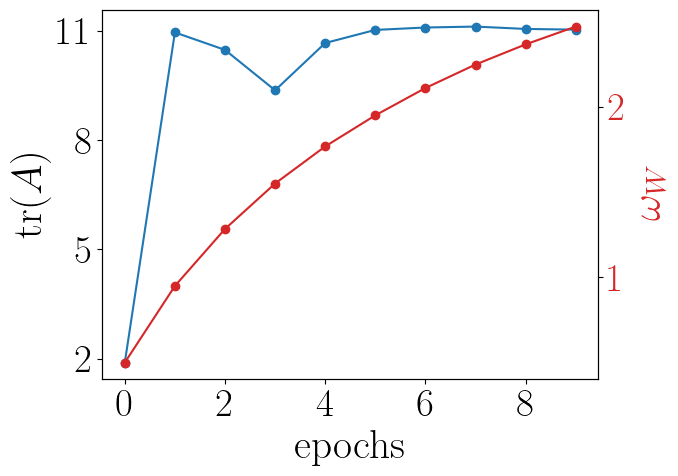

In [ ]:
print('w_gd: ', w_gd)
with nice_2d_plot(xlabel='epochs', ylabel='$\mathrm{tr}(A)$', xticks=np.arange(0, 20, 2), yticks=np.arange(-1, 15, 3)) as (fig4, ax4):
    ax4.plot(abs(np.array(loss_w)), '-o')#, label='$\mathrm{tr}(A)$')
    ax4s = ax4.twinx()
    color = 'tab:red'
    #ax4s.set_yticks(np.arange(0, 6, 1))
    ax4s.tick_params(axis='y', labelcolor=color, labelsize=28)
    ax4s.plot(np.abs(np.array(w_vals)[:, 1]), '-o', color=color)
    ax4s.set_ylabel('$\omega_W$', color=color, fontsize=30)
    
    #plt.savefig('../figures/bickley_loss.pdf', bbox_inches='tight', dpi=300)

In [48]:
## final approximation

# eigvals and eigenvectors approximation
eigvals_f, eigvecs_f = ranndy.operator_eig_decomp(
    w=w_gd,
    X=X,
    Y=Y,
    Z=None,
    n=n_eigfuncs,
    epsilon=1e-5,)


<>:6: SyntaxWarning: invalid escape sequence '\l'
<>:6: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_11817/1067190029.py:6: SyntaxWarning: invalid escape sequence '\l'
  with nice_2d_plot(xlabel='i', ylabel='$\lambda_i$', xticks=np.arange(0, 20, 2), yticks=np.arange(0, 1.2, 0.2)) as (fig5, ax5):


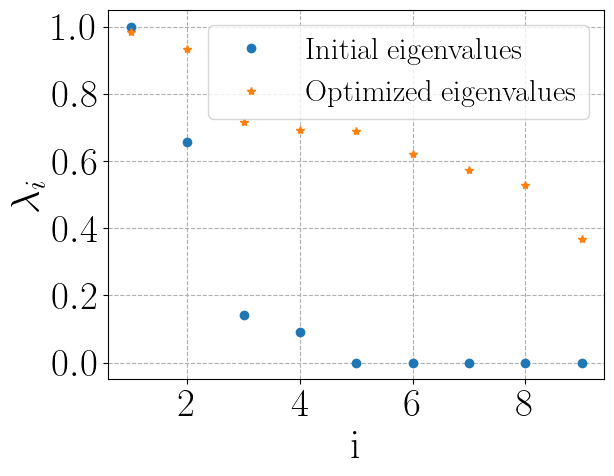

In [ ]:
## plotting eigenvalues

# plt.figure()
xv = jnp.arange(1, n_eigfuncs+1, 1)

with nice_2d_plot(xlabel='i', ylabel='$\lambda_i$', xticks=np.arange(0, 20, 2), yticks=np.arange(0, 1.2, 0.2)) as (fig5, ax5):
    ax5.plot(xv, eigvals_i[:], 'o', label='Initial eigenvalues')
    ax5.plot(xv, eigvals_f[:], '*', label='Optimized eigenvalues')
    #ax5.plot(xv, eigvals_vampnet, 'x')
    plt.legend(fontsize=22, loc='best')
    plt.grid(which="minor", linestyle=":")
    plt.grid(which="major", linestyle="--")
    #plt.savefig('../figures/bickley_eiganvalues.pdf', bbox_inches='tight', dpi=300)


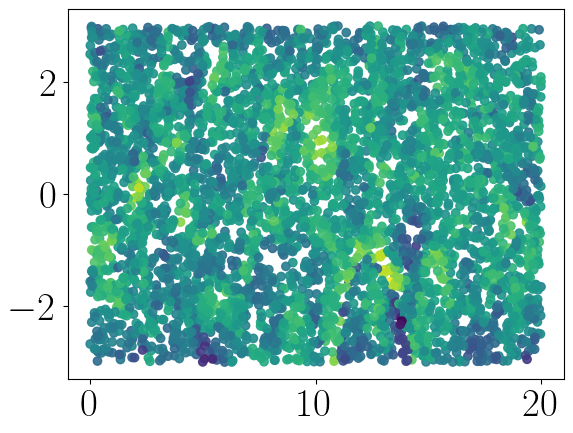

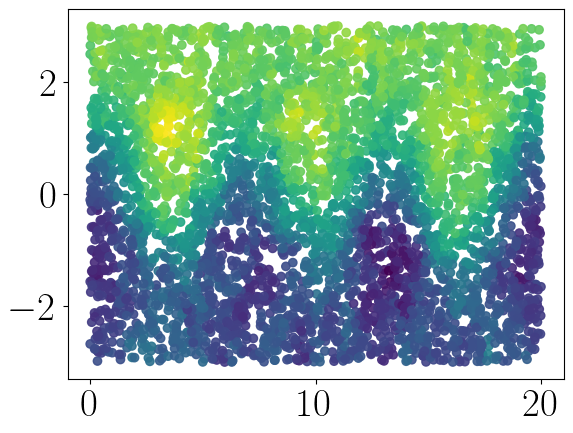

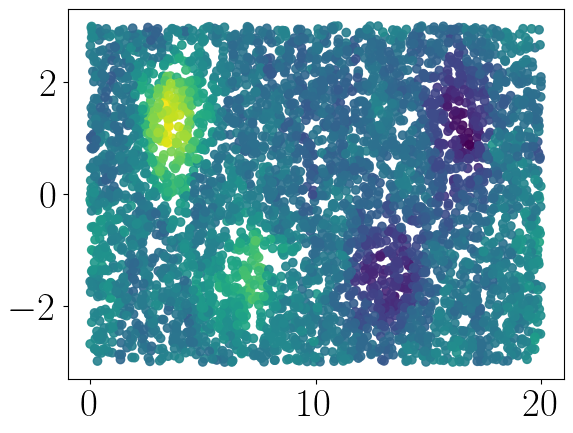

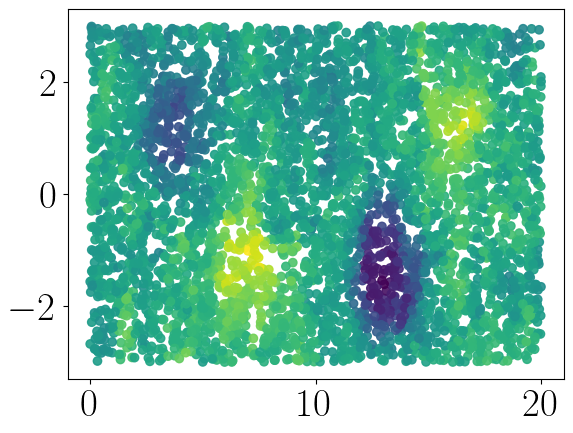

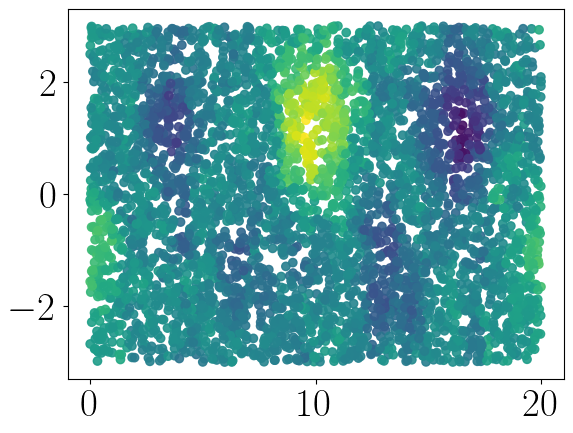

In [52]:
# plot initial eigenfunctions for ranndy

eigfuncs_f = ranndy.eigenfunctions(
        w=w_gd,
        eigvecs=eigvecs_f,
        domain=X,
        )
       
for i in range(5):
    #plt.figure(figsize=(3, 2))
    with nice_2d_plot():
        plt.scatter(Xa[0, :], Xa[1, :], c=eigfuncs_f[i, :], alpha=0.9)
    

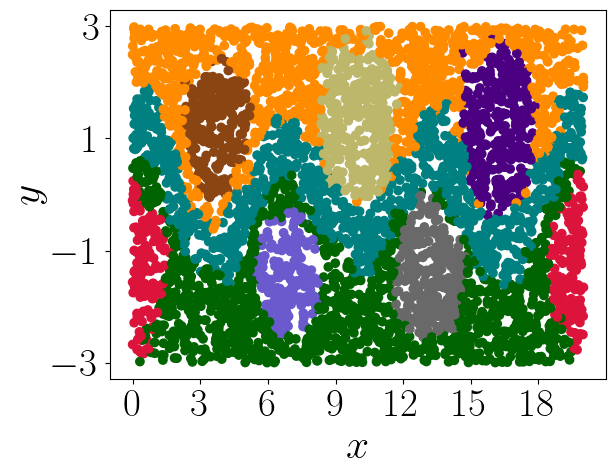

In [ ]:
## RaNNDy final eigf clustering

# cluster final eigenfunctiosn
c_f, l_f = sp.cluster.vq.kmeans2(np.real(eigfuncs_f[:9, :]).T, 9, iter=3000)

cols_f = [cluster_colors[label] for label in l_f]

with nice_2d_plot(xlabel='$x$', ylabel='$y$', xticks=np.arange(0, 25, 3), yticks=np.arange(-3, 4, 2)) as (fig6, ax6):
    ax6.scatter(Xa[0, :], Xa[1, :], c=cols_f, alpha=1)
    #plt.savefig('../figures/bickley_final_clustering.pdf', bbox_inches='tight', dpi=300)

## VAMPnets

In [12]:
vampnet = VAMPnets(
    X=X,
    operator=operator,
    hidden_sizes=[12000, 128],
    activation=activation,
    init_weights_dist=init_weights, 
    init_weights_std=init_weights_std,
    init_bias_dist=init_bias,
    init_bias_std=init_bias_std,
    #direct_link=direct_link,
    random_state=random_state,
)
key = random.PRNGKey(seed=0)
params_init = vampnet.init(key, jnp.ones_like(X), w=[None, None, None])

In [13]:
params_f, loss_vampnet = vampnet.training(params_init=params_init, X=X, Y=Y, epochs=10, optim='adam', lr=1e-4)

Epoch 0, Loss: -13.7968


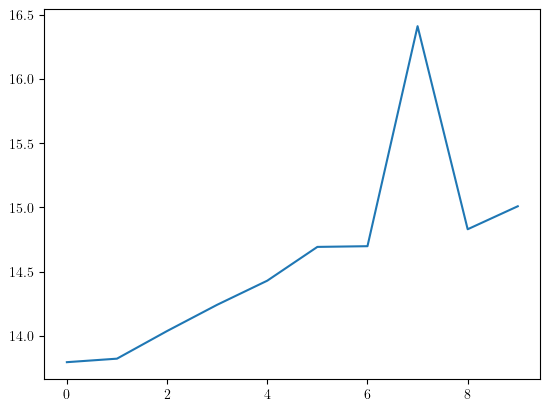

In [14]:
plt.plot(np.abs(loss_vampnet))

In [15]:
eigvals_vampnet, eigvecs_vampnet = vampnet.spectrum_approximation(params=params_f, X=X, Y=Y, n=9)
eigfuncs_vampnet = vampnet.eigenfunctions(params=params_f, eigvecs=eigvecs_vampnet.T)

/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


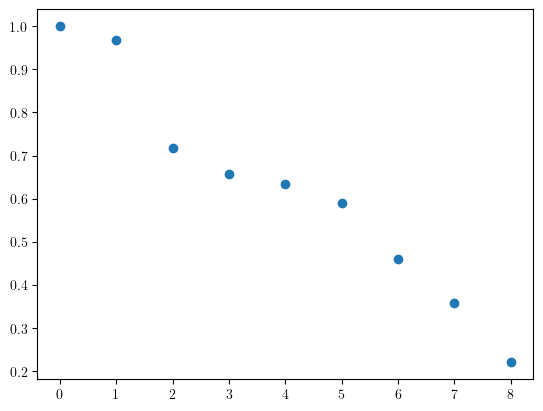

In [16]:
plt.plot(eigvals_vampnet, 'o')

/home/s2421480/Documents/PhD_final_year/ranndy_optimization/.venv/lib/python3.12/site-packages/matplotlib/axes/_axes.py:4733: ComplexWarning: Casting complex values to real discards the imaginary part
  c = np.asanyarray(c, dtype=float)


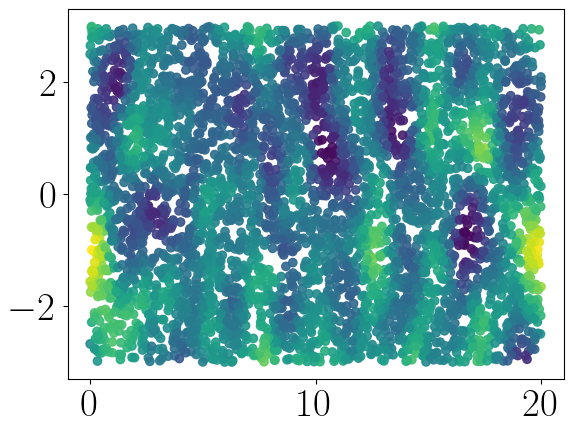

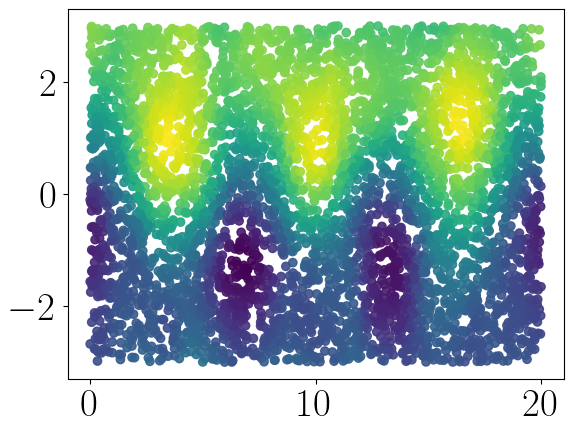

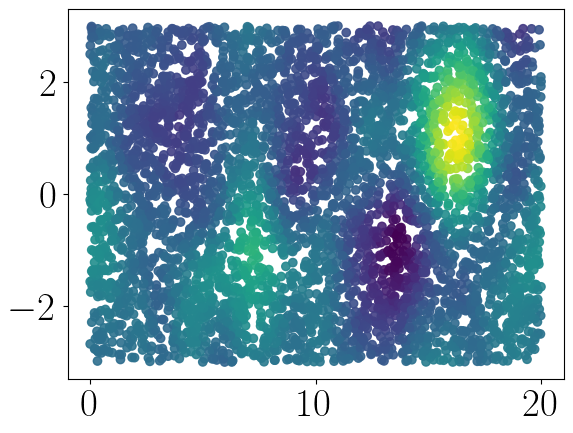

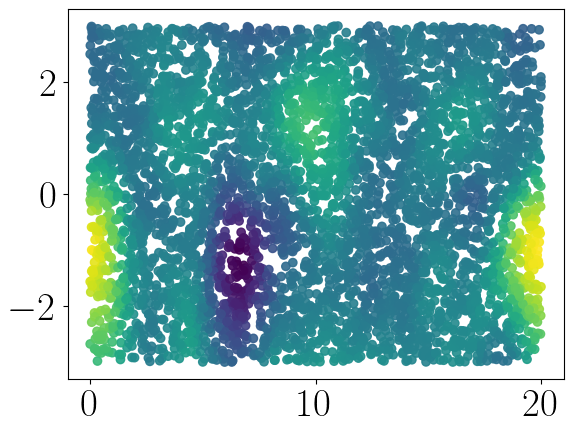

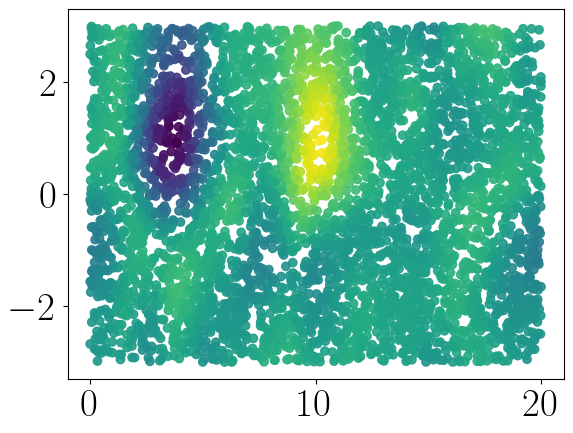

In [17]:

for i in range(5):
    #plt.figure(figsize=(3, 2))
    with nice_2d_plot():
        plt.scatter(Xa[0, :], Xa[1, :], c=eigfuncs_vampnet[i, :], alpha=0.9)

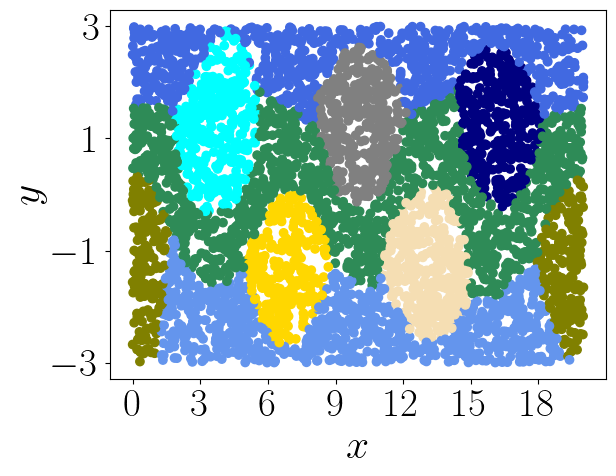

In [22]:

c_vampnet, l_vampnet = sp.cluster.vq.kmeans2(np.real(eigfuncs_vampnet[:9, :]).T, 9, iter=3000)
#cluster_colors = ["aqua", "seagreen", "navy", "gold", "cornflowerblue", "olive", "gray", "wheat", "royalblue"]
cols_vampnet = [cluster_colors[label] for label in l_vampnet]

with nice_2d_plot(xlabel='$x$', ylabel='$y$', xticks=np.arange(0, 25, 3), yticks=np.arange(-3, 4, 2)) as (fig8, ax8):
    ax8.scatter(Xa[0, :], Xa[1, :], c=cols_vampnet, alpha=1)

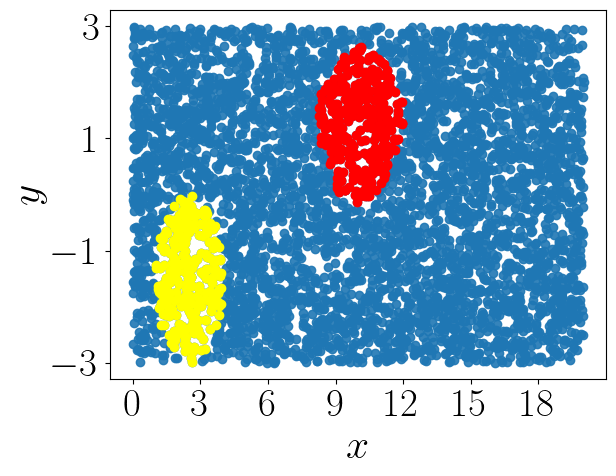

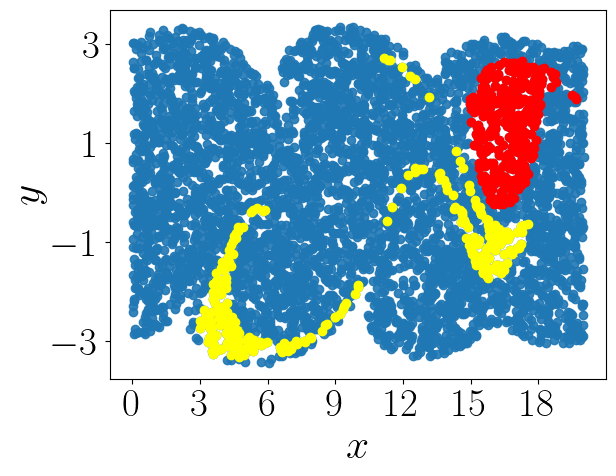

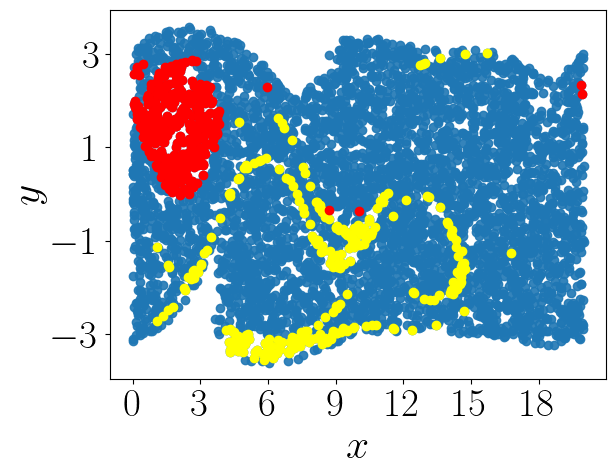

In [ ]:
# plot few snapshots

from scipy.spatial import cKDTree


X_cTree = cKDTree(Xa.T)
ind1 = X_cTree.query_ball_point(x=[2.5, -1.5], r=1.5)
timesteps = [0, 25, 50]  # pick any timesteps

co_indices = np.where(l_f == 2)[0]

for t in timesteps:
    
    with nice_2d_plot(xlabel='$x$', ylabel='$y$', xticks=np.arange(0, 22, 3), yticks=np.arange(-3, 4, 2)) as (fig7, ax7):     
        ax7.scatter(traj[:, t, 0], traj[:, t, 1], alpha=0.9)
        ax7.scatter(traj[ind1, t, 0], traj[ind1, t, 1], c="yellow",  marker="o")
        ax7.scatter(traj[co_indices, t, 0], traj[co_indices, t, 1], c="red",  marker="o")
        #fig7.savefig(f'../figures/bickley_timestep_{t}.pdf', bbox_inches='tight', dpi=300)